# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


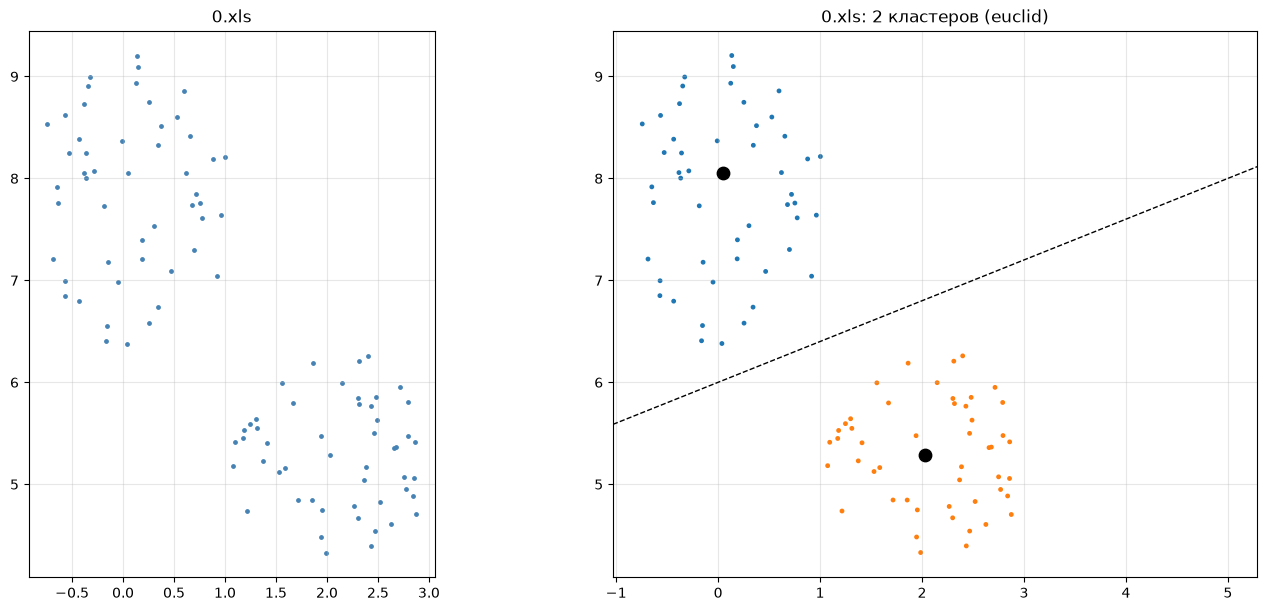

lines: [((0, 6), (5, 8))]
sizes: [50, 50]
center: (np.float64(0.0481), np.float64(8.0531))
center: (np.float64(2.0339), np.float64(5.2893))
Px*1000 = 1041.01  Py*1000 = 6671.17
ANSWER: 1041 6671



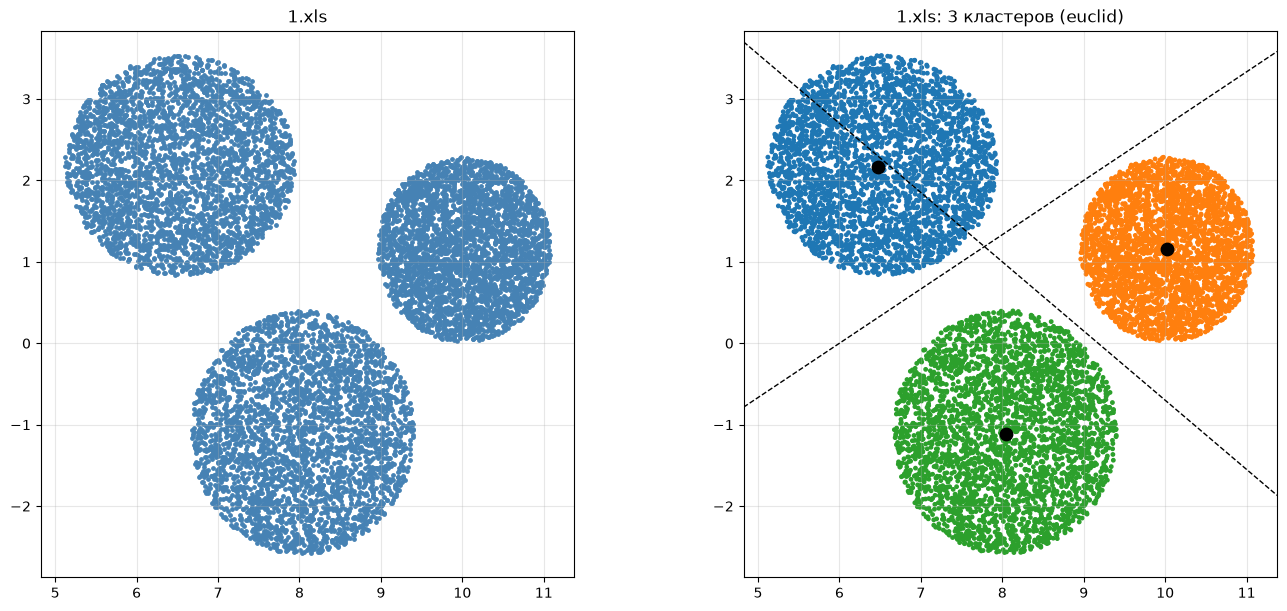

lines: [((6, 0), (9, 2)), ((8, 1), (10, -0.7))]
sizes: [3333, 3333, 3333]
center: (np.float64(6.47), np.float64(2.1698))
center: (np.float64(10.0225), np.float64(1.1542))
center: (np.float64(8.0401), np.float64(-1.1087))
Px*1000 = 8177.53  Py*1000 = 738.42
ANSWER: 8177 738



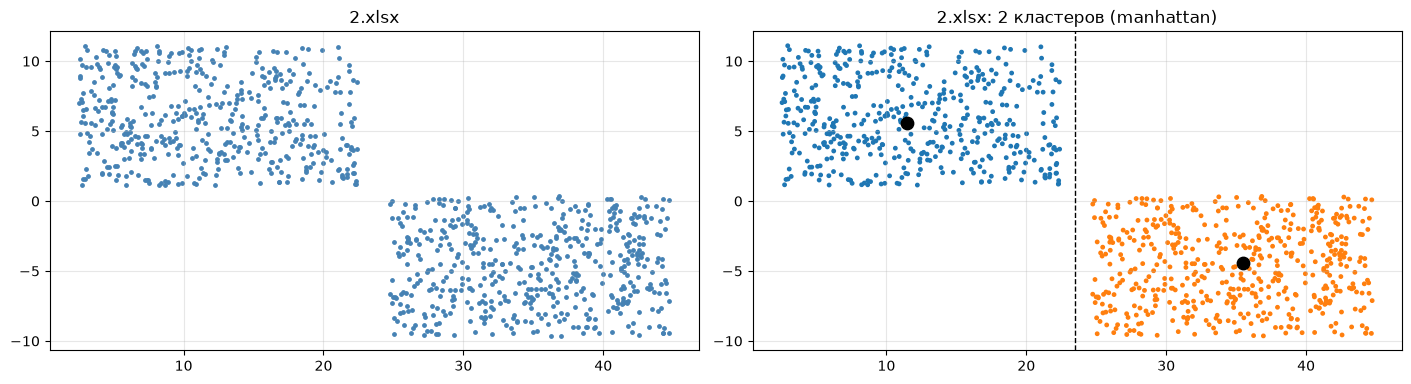

lines: [((23.5, 0), (23.5, 1))]
sizes: [476, 524]
center: (np.float64(11.5036), np.float64(5.5592))
center: (np.float64(35.5162), np.float64(-4.4498))
Px*1000 = 23509.9  Py*1000 = 554.68
ANSWER: 23509 554



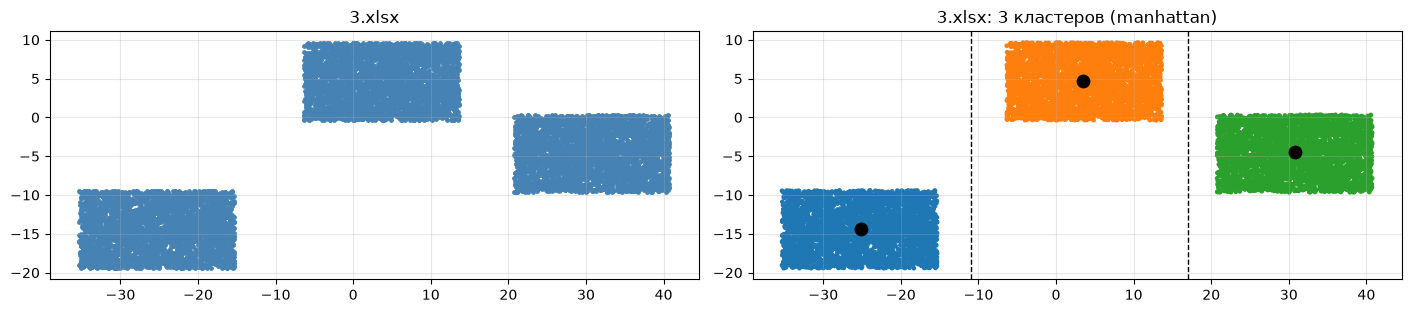

lines: [((-11, 0), (-11, 1)), ((17, 0), (17, 1))]
sizes: [3429, 3284, 3287]
center: (np.float64(-25.1308), np.float64(-14.4133))
center: (np.float64(3.5179), np.float64(4.6537))
center: (np.float64(30.8495), np.float64(-4.5172))
Px*1000 = 3078.89  Py*1000 = -4758.95
ANSWER: 3078 -4758



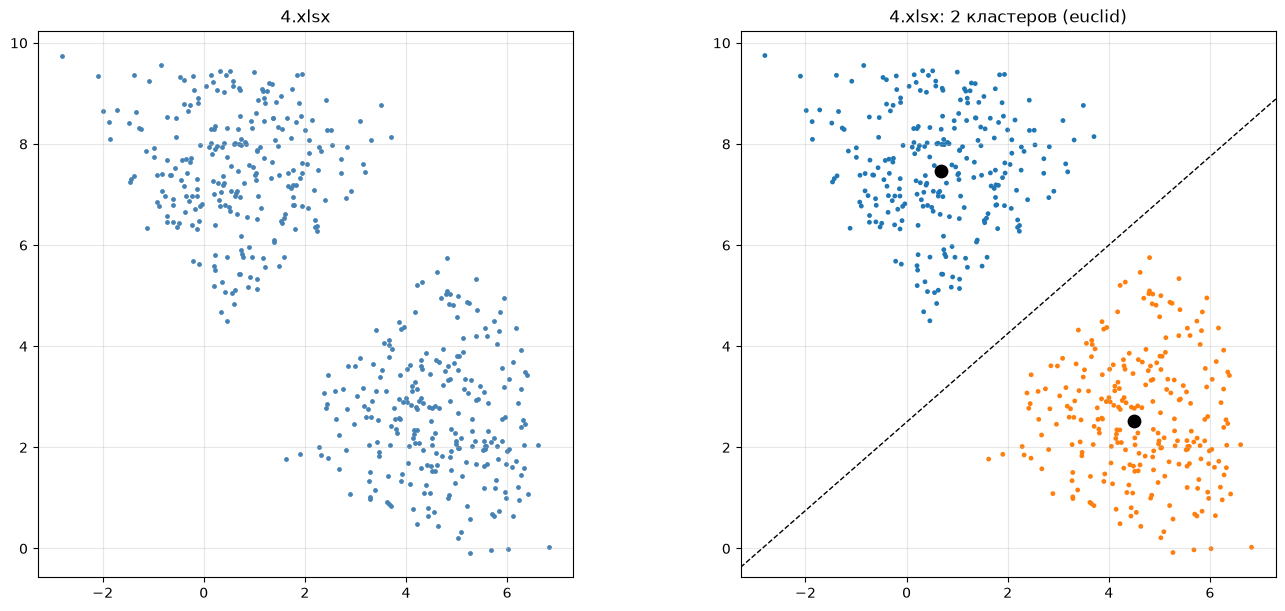

lines: [((0, 2.5), (4, 6))]
sizes: [250, 250]
center: (np.float64(0.6778), np.float64(7.4683))
center: (np.float64(4.4993), np.float64(2.5248))
Px*1000 = 2588.54  Py*1000 = 4996.57
ANSWER: 2588 4996



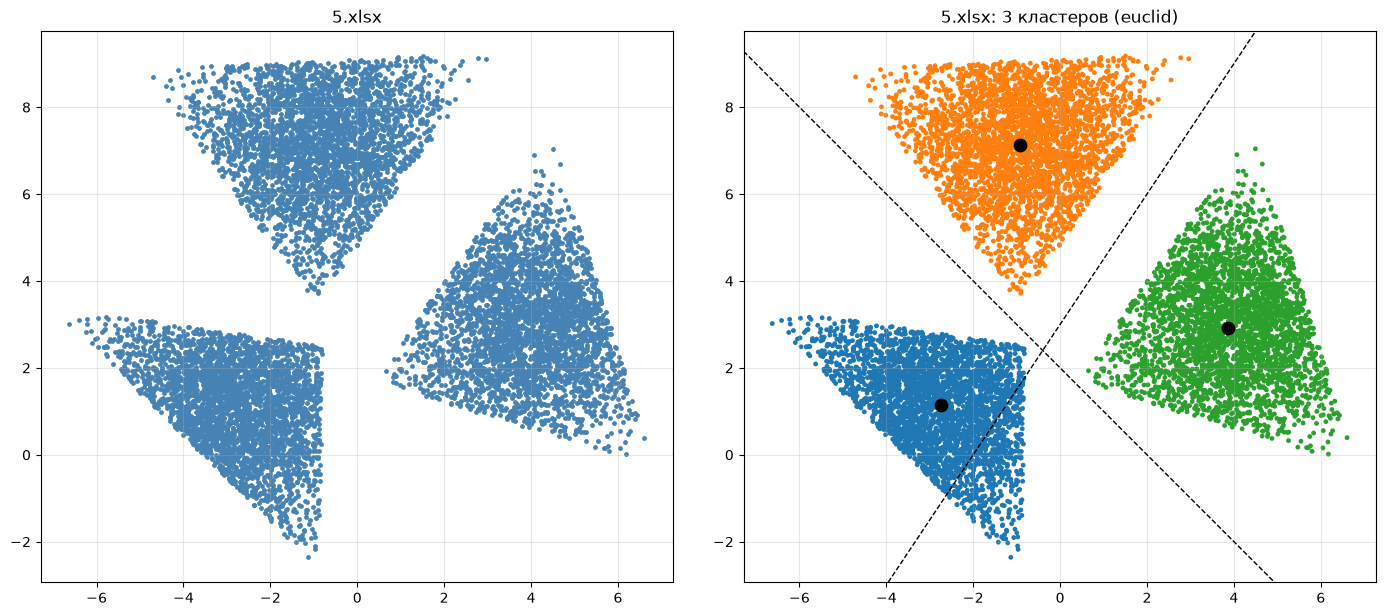

lines: [((2, 0), (0, 2)), ((0, 3), (2, 6))]
sizes: [3333, 3333, 3333]
center: (np.float64(-2.7497), np.float64(1.1431))
center: (np.float64(-0.924), np.float64(7.1199))
center: (np.float64(3.8586), np.float64(2.9072))
Px*1000 = 61.65  Py*1000 = 3723.36
ANSWER: 61 3723



,файл,метрика,кластеров,int(Px*1000),int(Py*1000)
0,0.xls,euclid,2,1041,6671
1,1.xls,euclid,3,8177,738
2,2.xlsx,manhattan,2,23509,554
3,3.xlsx,manhattan,3,3078,-4758
4,4.xlsx,euclid,2,2588,4996
5,5.xlsx,euclid,3,61,3723


In [64]:
def load_points(path):
    df = pd.read_excel(path, header=None)
    if isinstance(df.iloc[0, 0], str):
        df = df.iloc[1:]
    return df.astype(float).to_numpy()


def pairwise(A, B, metric):
    d = np.abs(A[:, None, :] - B[None, :, :])
    return np.sqrt((d ** 2).sum(-1)) if metric == "euclid" else d.sum(-1)


def side(X, p, q):
    dx, dy = q[0] - p[0], q[1] - p[1]
    n = np.hypot(dx, dy)
    a, b = -dy / n, dx / n
    return a * (X[:, 0] - p[0]) + b * (X[:, 1] - p[1])


def cluster_by_lines(X, lines):
    labels = np.full(len(X), len(lines))
    rest = np.ones(len(X), bool)
    for k, (p, q) in enumerate(lines):
        left = rest & (side(X, p, q) > 0)
        labels[left] = k
        rest &= ~left
    return labels


def cluster_center(P, metric):
    S = pairwise(P, P, metric).sum(axis=1)
    return P[int(S.argmin())]


def solve(path, metric, lines):
    X = load_points(path)
    labels = cluster_by_lines(X, lines)
    k = labels.max() + 1
    centers = np.array([cluster_center(X[labels == c], metric) for c in range(k)])
    px, py = centers.mean(axis=0) * 1000

    fig, ax = plt.subplots(1, 2, constrained_layout=True)

    ax[0].scatter(X[:, 0], X[:, 1], s=6, c="steelblue")
    ax[0].set_title(path)

    cmap = plt.get_cmap("tab10")
    ax[1].scatter(X[:, 0], X[:, 1], s=6, c=[cmap(l % 10) for l in labels])
    ax[1].scatter(centers[:, 0], centers[:, 1], s=80, c="black", zorder=3)
    for p, q in lines:
        ax[1].axline(p, q, color="black", ls="--", lw=1)
    ax[1].set_title(f"{path}: {k} кластеров ({metric})")

    for a in ax:
        a.set_aspect("equal")
        a.grid(alpha=0.3)
    plt.show()

    print("lines:", lines)
    print("sizes:", np.bincount(labels).tolist())
    for c in centers:
        print("center:", tuple(np.round(c, 4)))
    print("Px*1000 =", round(px, 2), " Py*1000 =", round(py, 2))
    print("ANSWER:", int(px), int(py))
    print()

    return dict(file=path, metric=metric, k=k, Px=int(px), Py=int(py))


TASKS = [
    ("0.xls",  "euclid",    [((0, 6), (5, 8))]),
    ("1.xls",  "euclid",    [((6, 0), (9, 2)), ((8, 1), (10, -0.7))]),
    ("2.xlsx", "manhattan", [((23.5, 0), (23.5, 1))]),
    ("3.xlsx", "manhattan", [((-11, 0), (-11, 1)), ((17, 0), (17, 1))]),
    ("4.xlsx", "euclid",    [((0, 2.5), (4, 6))]),
    ("5.xlsx", "euclid",    [((2, 0), (0, 2)), ((0, 3), (2, 6))]),
]

answers = [solve(f, m, lines) for f, m, lines in TASKS]
summary = pd.DataFrame(answers).rename(columns={
    "file": "файл", "metric": "метрика", "k": "кластеров",
    "Px": "int(Px*1000)", "Py": "int(Py*1000)",
})
display(summary)

# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [51]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [52]:
two_means =  
dbscan = 

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

SyntaxError: invalid syntax (3961450720.py, line 1)

In [ ]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    for name, algorithm in clustering_algorithms:
        t0 = time.time()